# AAM chord annotation — chroma, BeatNet and a Gaussian HMM

This Colab notebook uses **AAM songs 0001–1000**, with **600 training, 200 validation and 200 test songs**. It follows one workflow:

1. Read cleaned ground truth from the separate preprocessing notebook.
2. Extract 12 bass + 12 middle-register chroma values per interval.
3. Learn two Gaussian distributions and chord-transition probabilities.
4. Use BeatNet to find beats in audio, then Viterbi to predict a chord sequence.
5. Export time-aligned chord CSVs and measure performance.

**Main metric:** seconds with the correct chord / total audio duration. Timing errors and missing predictions reduce this score. The headline result comes from the **200 held-out test songs**; training and validation results are reported separately.

The model and caches are saved in Google Drive. On later visits, run the cells again: completed feature extraction, fitting, tuning and evaluation are loaded rather than repeated. A saved model also works with an arbitrary audio file in the final section.


## 1. Install packages and set folders
Your notebook runs in Colab's normal Python environment. BeatNet gets its own environment later, because its older `madmom` dependency needs a different setup.

**Run `AAM_Preprocessing_Colab.ipynb` through step 6 first.** Use the same `project_path` / `PROJECT` in both notebooks. This HMM notebook reads `0001_ground_truth.csv`, …, `1000_ground_truth.csv` from **`aam_cleaned_csv`**. Section 16 explains the connection; no old EDA notebook or ARFF export snippet is required.


In [36]:
%pip -q install librosa==0.11.0 soundfile pandas matplotlib scipy scikit-learn remotezip tqdm

from pathlib import Path
import hashlib
import json
import re
import shutil
import subprocess
import sys
import time
import os

import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from sklearn.covariance import LedoitWolf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score
from IPython.display import Audio, display
from tqdm.auto import tqdm
from google.colab import drive

os.environ["MPLBACKEND"] = "Agg"

drive.mount("/content/drive")

project_path = Path("/content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data")
ground_truth_path = project_path / "aam_cleaned_csv"
results_path = project_path / "aam_hmm_results"
model_path = results_path / "aam_hmm.npz"
# To load a different trained model, change model_path to that .npz file.

sample_rate = 22050
hop_length = 512
seed = 42
notes = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
chords = np.array([note + quality for note in notes for quality in ["maj", "min"]])
chord_to_id = {chord: i for i, chord in enumerate(chords)}

results_path.mkdir(parents=True, exist_ok=True)
local_path = Path("/content/aam")
local_path.mkdir(exist_ok=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Read the preprocessing notebook's cleaned CSVs
Audio is downloaded from the [AAM release](https://zenodo.org/records/5794629). The first-1,000 mixes ZIP is about **14.7 GB**, so we request individual mixes instead of extracting the whole archive. Once all songs are processed, total transferred audio is still substantial. Audio stays in `/content`; smaller model/feature/BeatNet caches stay in Drive.

**Ground truth comes from `AAM_Preprocessing_Colab.ipynb`.** That separate notebook downloads and cleans the annotations, then saves CSVs with interval end times. No source-annotation download or cleaning runs here.

The CSV's `chord` is in the original pitch, matching the audio. `chord_C`, `key_C` and transposition shifts are optional inspection fields; this HMM does not use them. It rotates chroma internally for each candidate chord root and needs no ground-truth key for a new recording.


In [37]:
base_url = "https://zenodo.org/records/5794629/files/"
audio_url = base_url + "0001-1000-audio-mixes.zip?download=1"

expected_ids = [f"{i:04d}" for i in range(1, 1001)]
beat_files = {}
for file_path in ground_truth_path.rglob("*_ground_truth.csv"):
    song_id = file_path.name.split("_")[0]
    assert song_id not in beat_files, f"Duplicate annotation: {song_id}"
    beat_files[song_id] = file_path

assert set(beat_files) == set(expected_ids), "Run AAM_Preprocessing_Colab.ipynb through step 6: expected all 1,000 cleaned CSVs in ground_truth_path."


### Validate the CSV intervals and labels
Each file must contain `time_s, end_time_s, bar, quarter, chord`. We map flat roots such as `Db` to `C#`; unknown chord types stop the run and known no-chord labels become `N`.

The preprocessing notebook exports `chord` in its original pitch. For compatibility with older CSVs, if `original_chord` exists we use it instead. A file declaring nonzero transposition without original labels or the new `chord_C` column is rejected to avoid training on mismatched audio and targets.


In [38]:
def normalize_chord(label):
    label = label.strip().strip("'\"")
    if label.lower() in ["n", "n.c.", "nc", "none", "x", "?"]:
        return "N"
    match = re.fullmatch(r"([A-G])([#b]?)(?::|_)?(maj|min|m|M)?", label)
    if match is None:
        raise ValueError(f"Unsupported chord: {label}")
    letter, accidental, quality = match.groups()
    root = {"C": 0, "D": 2, "E": 4, "F": 5, "G": 7, "A": 9, "B": 11}[letter]
    root += {None: 0, "": 0, "#": 1, "b": -1}[accidental]
    quality = "min" if quality in ["min", "m"] else "maj"
    return notes[root % 12] + quality



def read_ground_truth(file_path):
    table = pd.read_csv(file_path)
    required = {"time_s", "end_time_s", "bar", "quarter", "chord"}
    assert required.issubset(table.columns), f"Missing CSV columns: {file_path.name}"
    if "original_chord" in table:
        table["chord"] = table.original_chord
    elif "transpose_semitones" in table and "chord_C" not in table:
        assert table.transpose_semitones.eq(0).all(), "Use original-pitch chords, not C-normalized targets."
    table = table.rename(columns={"time_s": "start", "end_time_s": "end"})
    table = table[["start", "end", "bar", "quarter", "chord"]].copy()
    for column in ["start", "end", "bar", "quarter"]:
        table[column] = pd.to_numeric(table[column])
    assert table.chord.notna().all(), f"Missing chord labels: {file_path.name}"
    table["chord"] = table.chord.map(normalize_chord)

    assert len(table) > 1, f"Too few rows: {file_path.name}"
    assert np.isfinite(table[["start", "end", "bar", "quarter"]]).all().all()
    assert (np.diff(table.start) > 0).all(), f"Duplicate/backward times: clean {file_path.name} first."
    assert table.start.iloc[0] >= 0 and (table.end > table.start).all()
    assert (table.end.iloc[:-1].to_numpy() <= table.start.iloc[1:].to_numpy() + 1e-7).all()
    assert np.allclose(table[["bar", "quarter"]], np.round(table[["bar", "quarter"]]))
    assert table.bar.ge(1).all() and table.quarter.isin([1, 2, 3, 4]).all()
    return table


In [39]:
ground_truth = {song_id: read_ground_truth(beat_files[song_id]) for song_id in expected_ids}

# A changed annotation or feature setting gets a different cache/model identity.
annotation_hash = hashlib.sha256()
for song_id in expected_ids:
    annotation_hash.update(song_id.encode())
    annotation_hash.update(ground_truth[song_id].to_csv(index=False).encode())
settings = {"version": 1, "sr": sample_rate, "hop": hop_length,
            "features": "CQT84_C1_bass3_mid2_central90_L2", "audio_url": audio_url,
            "annotations": annotation_hash.hexdigest(), "chords": chords.tolist()}
run_id = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:16]
cache_path = results_path / "cache" / run_id
cache_path.mkdir(parents=True, exist_ok=True)

print("Cleaned songs:", len(ground_truth))
print("No-chord rows:", sum(table.chord.eq("N").sum() for table in ground_truth.values()))
display(ground_truth["0002"].head(8))


Cleaned songs: 1000
No-chord rows: 6210


,start,end,bar,quarter,chord
0,0.000000,0.431655,1,1,F#maj
1,0.431655,0.863309,1,2,F#maj
2,0.863309,1.294964,1,3,F#maj
3,1.294964,1.726619,1,4,F#maj
4,1.726619,2.158273,2,1,G#min
5,2.158273,2.589928,2,2,G#min
6,2.589928,3.021583,2,3,G#min
7,3.021583,3.453237,2,4,G#min


## 3. Split by song: 60 / 20 / 20
All beats from a song stay in one split. Training learns the model. Validation chooses how strongly chord transitions influence predictions. Test songs are used only after that choice is fixed.

This is a reproducible random split, not a guarantee of independence between repeated compositions or related arrangements in a generated dataset. If you later identify song families, split by those families instead.


In [40]:
train_ids, remaining_ids = train_test_split(expected_ids, test_size=0.4, random_state=seed)
val_ids, test_ids = train_test_split(remaining_ids, test_size=0.5, random_state=seed)
split = {"train": sorted(train_ids), "validation": sorted(val_ids), "test": sorted(test_ids)}
(cache_path / "split.json").write_text(json.dumps(split, indent=2))
print({name: len(ids) for name, ids in split.items()})


{'train': 600, 'validation': 200, 'test': 200}


## 4. Load one mix and calculate chroma
The Constant-Q Transform (CQT) groups frequencies into musical semitones. We sum three low octaves into **12 bass pitch classes**, and two middle octaves into **12 middle pitch classes**. The result has 24 values per audio frame.

The first audio request opens the remote ZIP. If Zenodo rejects range requests, rerun later or place an extracted audio-mixes folder in `audio_folder`; the notebook never silently downloads the entire 14.7 GB ZIP. Caches let completed songs survive a Colab restart.


In [41]:
audio_folder = local_path / "audio"  # Can point to an extracted folder in Drive instead.
audio_folder.mkdir(exist_ok=True)
audio_archive = None


def get_audio_path(song_id):
    global audio_archive
    matches = list(audio_folder.rglob(f"{song_id}_mix.*"))
    if matches:
        assert len(matches) == 1, f"Duplicate mix: {song_id}"
        return matches[0]
    if audio_archive is None:
        from remotezip import RemoteZip
        tqdm.write("Opening the remote AAM audio ZIP index…")
        audio_archive = RemoteZip(audio_url, timeout=120)
    matches = [name for name in audio_archive.namelist()
               if re.search(rf"(^|/){song_id}_mix\.(flac|wav|mp3)$", name)]
    assert len(matches) == 1, f"Mix not found in archive: {song_id}"
    file_path = audio_folder / Path(matches[0]).name
    temporary = file_path.with_suffix(".part")
    tqdm.write(f"Song {song_id}: downloading audio…")
    with audio_archive.open(matches[0]) as source, open(temporary, "wb") as target:
        shutil.copyfileobj(source, target)
    temporary.replace(file_path)
    return file_path


def compute_chroma(audio):
    cqt = np.abs(librosa.cqt(audio, sr=sample_rate, hop_length=hop_length,
                            fmin=librosa.note_to_hz("C1"), n_bins=84))
    bass = cqt[:36].reshape(3, 12, -1).sum(axis=0)
    middle = cqt[36:60].reshape(2, 12, -1).sum(axis=0)
    return np.vstack([bass, middle]).astype(np.float32)


def get_chroma(song_id):
    file_path = cache_path / f"{song_id}_chroma.npz"
    if file_path.exists():
        with np.load(file_path) as saved:
            return saved["chroma"], float(saved["duration"])
    started = time.perf_counter()
    audio_path = get_audio_path(song_id)
    tqdm.write(f"Song {song_id}: loading audio and calculating CQT chroma…")
    audio, sr = librosa.load(audio_path, sr=sample_rate, mono=True)
    duration = len(audio) / sr
    chroma = compute_chroma(audio)
    temporary = file_path.with_suffix(".tmp.npz")
    np.savez_compressed(temporary, chroma=chroma, duration=duration)
    temporary.replace(file_path)
    tqdm.write(f"Song {song_id}: chroma saved ({time.perf_counter() - started:.1f} s, including audio loading/download).")
    return chroma, duration


### Average chroma inside each interval
We use the middle 90% of each interval to reduce leakage around chord changes. Bass and middle bands are normalized separately so volume has less influence. A short interval with no frame inside uses its nearest frame.

Training uses annotated quarter intervals. The complete system uses **BeatNet intervals**, without accessing the ground truth. The last annotated quarter ends at the segment end marker, not an invented extra beat.


In [42]:
def interval_features(chroma, starts, ends):
    frame_times = librosa.frames_to_time(np.arange(chroma.shape[1]), sr=sample_rate, hop_length=hop_length)
    features = []
    for start, end in zip(starts, ends):
        assert end > start
        margin = 0.05 * (end - start)
        left = np.searchsorted(frame_times, start + margin)
        right = np.searchsorted(frame_times, end - margin)
        left = min(left, chroma.shape[1] - 1)
        right = min(max(right, left + 1), chroma.shape[1])
        vector = chroma[:, left:right].mean(axis=1).reshape(2, 12)
        vector = vector / np.maximum(np.linalg.norm(vector, axis=1, keepdims=True), 1e-10)
        features.append(vector.reshape(24))
    return np.array(features).reshape(-1, 24)


def get_training_features(song_id):
    chroma, duration = get_chroma(song_id)
    table = ground_truth[song_id]
    assert table.start.iloc[-1] < duration, f"Annotations exceed audio: {song_id}"
    assert table.end.iloc[-1] <= duration + 0.1, f"End marker exceeds audio: {song_id}"
    ends = np.minimum(table.end.to_numpy(), duration)
    features = interval_features(chroma, table.start.to_numpy(), ends)
    return features, table.chord.to_numpy(), ends - table.start.to_numpy()


## 5. Learn major/minor Gaussian distributions
For a labeled D-major example, rotate each chroma band down two semitones so its root aligns with C. Pool these examples with all other major chords. Do the same for minor chords. We therefore learn **two shared distributions**, not 24 unrelated models.

Each Gaussian learns a mean (typical chroma) and covariance (variation and correlations). `LedoitWolf` estimates a stable covariance. At prediction time we try all 12 candidate roots and both qualities; no true chord or key is needed.


In [43]:
def shift_to_C(features, root):
    bands = features.reshape(-1, 2, 12)
    return np.roll(bands, -root, axis=2).reshape(-1, 24)


def fit_gaussians(song_ids):
    samples = [[], []]
    training_bar = tqdm(song_ids, desc="Training features", unit="song")
    for song_id in training_bar:
        cached = (cache_path / f"{song_id}_chroma.npz").exists()
        training_bar.set_postfix(song=song_id, chroma="cached" if cached else "new")
        features, labels, _ = get_training_features(song_id)
        for chord_id, chord in enumerate(chords):
            selected = features[labels == chord]
            if len(selected):
                samples[chord_id % 2].append(shift_to_C(selected, chord_id // 2))
    means, covariances = [], []
    for quality, group in enumerate(samples):
        assert group, "No major or minor training examples."
        training_samples = np.vstack(group)
        title = ["major", "minor"][quality]
        tqdm.write(f"Fitting {title} Gaussian: {len(training_samples):,} quarter examples…")
        started = time.perf_counter()
        estimator = LedoitWolf().fit(training_samples)
        tqdm.write(f"{title.capitalize()} Gaussian fitted in {time.perf_counter() - started:.1f} s.")
        means.append(estimator.location_)
        covariances.append(estimator.covariance_ + 1e-4 * np.eye(24))
    return np.array(means), np.array(covariances)


def emission_scores(features, model):
    scores = np.empty((len(features), 24))
    for root in range(12):
        aligned = shift_to_C(features, root)
        for quality in range(2):
            scores[:, 2 * root + quality] = multivariate_normal.logpdf(
                aligned, mean=model["means"][quality], cov=model["covariances"][quality])
    return scores


## 6. Learn transitions and decode with Viterbi
The transition matrix describes which chord is likely to follow the previous chord. We pool transitions by **previous quality, root movement, next quality**. This shares examples across keys. A small count of 0.5 prevents impossible transitions just because training never saw one.

Viterbi finds the best whole sequence, considering chroma evidence and transitions together. `weight = 0` gives independent Gaussian predictions; larger weights favor typical transitions more strongly. Weight 1 is the ordinary HMM; other weights are a weighted decoding variant. The initial chord probabilities are uniform.


In [44]:
def fit_transitions(song_ids):
    counts = np.full((2, 12, 2), 0.5)
    for song_id in song_ids:
        labels = ground_truth[song_id].chord.to_numpy()
        for previous, current in zip(labels[:-1], labels[1:]):
            if previous == "N" or current == "N":
                continue
            i, j = chord_to_id[previous], chord_to_id[current]
            counts[i % 2, (j // 2 - i // 2) % 12, j % 2] += 1
    probabilities = counts / counts.sum(axis=(1, 2), keepdims=True)
    transitions = np.empty((24, 24))
    for i in range(24):
        for j in range(24):
            transitions[i, j] = probabilities[i % 2, (j // 2 - i // 2) % 12, j % 2]
    return transitions


def viterbi(scores, transitions, weight):
    if len(scores) == 0:
        return np.array([], dtype=int)
    best = np.empty_like(scores)
    back = np.zeros(scores.shape, dtype=int)
    best[0] = scores[0] - np.log(scores.shape[1])
    log_transitions = weight * np.log(transitions)
    for t in range(1, len(scores)):
        candidates = best[t - 1, :, None] + log_transitions
        back[t] = candidates.argmax(axis=0)
        best[t] = scores[t] + candidates[back[t], np.arange(scores.shape[1])]
    path = np.empty(len(scores), dtype=int)
    path[-1] = best[-1].argmax()
    for t in range(len(scores) - 2, -1, -1):
        path[t] = back[t + 1, path[t + 1]]
    return path


## 7. Fit once, then save/load the model
We save a portable **`.npz` model file**, rather than CSV, because means, covariance matrices and transitions have different shapes. It contains ordinary arrays and JSON metadata; loading does not require unpickling Python objects.

An intermediate fitted model is saved **before validation**. If tuning is interrupted, fitting does not repeat. Each file records the feature settings, annotation fingerprint and exact song split; a mismatched checkpoint stops the run. Retraining after changes uses a different `model_path`.

**Runtime and progress:** On a first run, audio downloads and chroma extraction usually dominate this cell; fitting the two small Gaussian models and counting transitions are separate stages. A live bar shows completed songs, elapsed time, approximate remaining time, current song and whether chroma is cached. New audio/CQT stages print messages before and after they run. The first song may be slower due to initialization; ETA is approximate, especially with a mixture of cached and uncached songs.


In [45]:
metadata = {"settings": settings, "split": split}
fitted_path = model_path.with_name(model_path.stem + "_fitted.npz")


def save_model(file_path, model):
    file_path.parent.mkdir(parents=True, exist_ok=True)
    temporary = file_path.with_suffix(".tmp.npz")
    np.savez_compressed(temporary, means=model["means"], covariances=model["covariances"],
                        transitions=model["transitions"], weight=model["weight"],
                        metadata=json.dumps(metadata))
    temporary.replace(file_path)


def load_model(file_path):
    with np.load(file_path, allow_pickle=False) as saved:
        assert json.loads(str(saved["metadata"])) == metadata, "Model settings/split differ. Use the matching files or a new model_path."
        return {"means": saved["means"], "covariances": saved["covariances"],
                "transitions": saved["transitions"], "weight": float(saved["weight"])}


if model_path.exists():
    model = load_model(model_path)
    print("Loaded fully trained and tuned model:", model_path)
elif fitted_path.exists():
    model = load_model(fitted_path)
    print("Loaded fitted model; validation remains.")
else:
    print("Starting model fitting on", len(split["train"]), "songs.", flush=True)
    fit_started = time.perf_counter()
    means, covariances = fit_gaussians(split["train"])
    print("Learning chord transitions…", flush=True)
    model = {"means": means, "covariances": covariances,
             "transitions": fit_transitions(split["train"]), "weight": 1.0}
    save_model(fitted_path, model)
    print(f"Model fitting finished in {(time.perf_counter() - fit_started) / 60:.1f} minutes.", flush=True)
    print("Fitted model saved:", fitted_path)


Loaded fully trained and tuned model: /content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data/aam_hmm_results/aam_hmm.npz


## 8. Keep BeatNet in a separate Python environment
BeatNet uses its pretrained model 1 in offline DBN mode, just as in the supplied pipeline. **We train the chord HMM, not BeatNet.** The subprocess is the only infrastructure-heavy part: it keeps older BeatNet/madmom dependencies away from the main notebook.

Installation runs once per fresh Colab runtime and may take several minutes. The environment itself is temporary. Detected beats are saved in Drive and do not need to be detected again. See the [BeatNet documentation](https://github.com/mjhydri/BeatNet).


In [46]:
beatnet_python = Path("/content/beatnet39/bin/python")
ready_file = Path("/content/beatnet39/ready")
if not ready_file.exists():
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "uv"], check=True)
    subprocess.run(["uv", "python", "install", "3.9"], check=True)
    subprocess.run(["uv", "venv", "/content/beatnet39", "--python", "3.9", "--seed"], check=True)
    subprocess.run(["apt-get", "-qq", "update"], check=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "portaudio19-dev"], check=True)
    pip_command = [str(beatnet_python), "-m", "pip", "install", "-q"]
    subprocess.run(pip_command + ["setuptools<81", "wheel", "numpy==1.23.5",
                   "numba==0.57.1", "llvmlite==0.40.1", "cython<3", "scipy==1.10.1",
                   "librosa==0.10.2.post1", "torch==2.2.2", "mido", "matplotlib",
                   "tensorboard", "pyyaml", "pyaudio"], check=True)
    subprocess.run(pip_command + ["--no-build-isolation", "madmom==0.16.1"], check=True)
    subprocess.run(pip_command + ["--no-deps", "BeatNet==1.1.3"], check=True)
    ready_file.touch()


In [47]:
beatnet_script = Path("/content/run_beatnet.py")
beatnet_script.write_text("""import sys
import numpy as np
import matplotlib
matplotlib.use('Agg')
from BeatNet.BeatNet import BeatNet
estimator = BeatNet(1, mode='offline', inference_model='DBN', plot=[], thread=False)
events = np.asarray(estimator.process(sys.argv[1]))
if events.ndim != 2 or events.shape[1] != 2:
    raise ValueError('Unexpected BeatNet output shape')
np.save(sys.argv[2], events)
""")


def detect_beats(audio_path, file_path):
    if not file_path.exists():
        tqdm.write(f"Running BeatNet on {Path(audio_path).name}…")
        started = time.perf_counter()
        temporary = file_path.with_suffix(".tmp.npy")
        subprocess.run([str(beatnet_python), str(beatnet_script), str(audio_path), str(temporary)], check=True)
        temporary.replace(file_path)
        tqdm.write(f"BeatNet finished in {time.perf_counter() - started:.1f} s; beats saved.")
    events = np.load(file_path)
    assert events.ndim == 2 and events.shape[1] == 2 and np.isfinite(events).all()
    assert (np.diff(events[:, 0]) > 0).all(), "BeatNet returned unordered beats."
    return events


def get_beatnet_features(song_id):
    file_path = cache_path / f"{song_id}_beatnet_features.npz"
    if file_path.exists():
        with np.load(file_path) as saved:
            return saved["features"], saved["events"], float(saved["duration"])
    chroma, duration = get_chroma(song_id)
    beat_path = cache_path / f"{song_id}_beatnet_model1.npy"
    # No audio download is needed if beat timestamps are already cached.
    audio_path = get_audio_path(song_id) if not beat_path.exists() else None
    events = detect_beats(audio_path, beat_path)
    events = events[(events[:, 0] >= 0) & (events[:, 0] < duration)]
    starts = events[:, 0]
    ends = np.append(starts[1:], duration) if len(starts) else np.array([])
    features = interval_features(chroma, starts, ends)
    temporary = file_path.with_suffix(".tmp.npz")
    np.savez_compressed(temporary, features=features, events=events, duration=duration)
    temporary.replace(file_path)
    return features, events, duration


## 9. Turn predictions into intervals and measure correct time
Every detected beat gets a chord lasting until the next beat; the final chord lasts until the audio ends. Before the first BeatNet beat we have no prediction. We do **not** fill that missing time with the first chord.

To compare two different time grids, combine their interval boundaries. Between adjacent boundaries both labels are constant, so a correct interval contributes its exact duration. No 50 ms sampling approximation is used.

- **Correct-time ratio (main):** correct seconds / full audio duration.
- **Scored-time ratio:** correct seconds / annotated major/minor seconds, shown separately.
- **Coverage:** seconds with a prediction / full audio duration.

The model has 24 major/minor states and cannot predict `N`. No-chord or unannotated time contributes zero correct seconds to the main metric. This is explicit rather than silently removed. Enharmonic names are normalized; two different major/minor triads are not treated as equivalent.


In [48]:
def prediction_table(events, duration, labels):
    starts = events[:, 0]
    ends = np.append(starts[1:], duration) if len(starts) else np.array([])
    return pd.DataFrame({"start": starts, "end": ends, "chord": labels})


def labels_at(times, table):
    output = np.full(len(times), "UNANNOTATED", dtype="<U16")
    if len(table) == 0:
        return output
    indices = np.searchsorted(table.start.to_numpy(), times, side="right") - 1
    safe_indices = np.clip(indices, 0, len(table) - 1)
    valid = (indices >= 0) & (times < table.end.to_numpy()[safe_indices])
    output[valid] = table.chord.to_numpy()[safe_indices[valid]]
    return output


def time_metrics(truth, prediction, duration):
    boundaries = np.unique(np.clip(np.concatenate([
        [0, duration], truth.start, truth.end, prediction.start, prediction.end]), 0, duration))
    lengths = np.diff(boundaries)
    midpoints = (boundaries[:-1] + boundaries[1:]) / 2
    true_labels = labels_at(midpoints, truth)
    predicted_labels = labels_at(midpoints, prediction)
    scored = np.isin(true_labels, chords)
    correct_seconds = lengths[scored & (true_labels == predicted_labels)].sum()
    scored_seconds = lengths[scored].sum()
    coverage_seconds = lengths[np.isin(predicted_labels, chords)].sum()
    return {"correct_seconds": correct_seconds, "duration_seconds": duration,
            "scored_seconds": scored_seconds, "coverage_seconds": coverage_seconds,
            "correct_time_ratio": correct_seconds / duration,
            "scored_time_ratio": correct_seconds / scored_seconds if scored_seconds else np.nan,
            "coverage": coverage_seconds / duration}


def export_predictions(prediction, events):
    table = prediction.rename(columns={"start": "start_time_s", "end": "end_time_s"}).copy()
    quarters = events[:, 1].astype(int)
    table["quarter"] = quarters
    bars = np.cumsum(quarters == 1).astype(float)
    bars[bars == 0] = np.nan
    table["bar"] = bars
    bpm = np.full(len(events), np.nan)
    if len(events) > 1:
        bpm[:-1] = 60 / np.diff(events[:, 0])
        bpm[-1] = bpm[-2]
    table["bpm"] = bpm
    return table



## 10. Tune the weight on all 200 validation songs
We choose the transition weight using the **main correct-time metric with BeatNet beats**. This matches the system we intend to deploy. Each candidate uses the same Gaussian model and transitions, learned only from training songs. Weight 0 is the Gaussian-only baseline. A simple fixed-transition HMM is also retained as a baseline later.

Intermediate validation totals are saved after each song, so an interruption does not restart tuning. Ties select the first, lowest weight. Test songs never enter this loop.

A live progress bar covers only unfinished validation songs, with elapsed time and approximate remaining time. BeatNet prints its start and completion. A fully saved model skips this cell’s tuning loop.


In [49]:
weights = [0.0, 0.5, 1.0, 2.0, 4.0, 6.0, 8.0]
validation_path = cache_path / "validation_progress.json"

if not model_path.exists():
    progress = json.loads(validation_path.read_text()) if validation_path.exists() else {}
    pending_ids = [song_id for song_id in split["validation"] if song_id not in progress]
    print(f"Validation: {len(progress)} saved songs; {len(pending_ids)} remaining.", flush=True)
    validation_bar = tqdm(pending_ids, desc="Validation", unit="song")
    for song_id in validation_bar:
        validation_bar.set_postfix(song=song_id, stage="BeatNet + 7 weights")
        if song_id not in progress:
            features, events, duration = get_beatnet_features(song_id)
            scores = emission_scores(features, model) if len(features) else np.empty((0, 24))
            correct = []
            for weight in weights:
                labels = chords[viterbi(scores, model["transitions"], weight)]
                prediction = prediction_table(events, duration, labels)
                correct.append(float(time_metrics(ground_truth[song_id], prediction, duration)["correct_seconds"]))
            progress[song_id] = {"correct": correct, "duration": duration}
            temporary = validation_path.with_suffix(".tmp")
            temporary.write_text(json.dumps(progress))
            temporary.replace(validation_path)
    totals = np.sum([progress[song_id]["correct"] for song_id in split["validation"]], axis=0)
    total_time = sum(progress[song_id]["duration"] for song_id in split["validation"])
    validation_scores = totals / total_time
    model["weight"] = weights[int(np.argmax(validation_scores))]
    pd.DataFrame({"weight": weights, "correct_time_ratio": validation_scores}).to_csv(
        cache_path / "validation_weights.csv", index=False)
    save_model(model_path, model)
    print("Validation finished; tuned model saved.", flush=True)
else:
    print("Validation skipped: the fully trained and tuned model is already saved.", flush=True)

print("Selected transition weight:", model["weight"])
print("Reusable model:", model_path)
if (cache_path / "validation_weights.csv").exists():
    display(pd.read_csv(cache_path / "validation_weights.csv"))


Validation skipped: the fully trained and tuned model is already saved.
Selected transition weight: 4.0
Reusable model: /content/drive/MyDrive/Femman/DT2470 Music Informatics/DT2470 Project/full_data/aam_hmm_results/aam_hmm.npz


,weight,correct_time_ratio
0,0.0,0.759214
1,0.5,0.817446
2,1.0,0.831169
3,2.0,0.845555
4,4.0,0.848908
5,6.0,0.839884
6,8.0,0.827454


## 11. Beat accuracy and timing diagnostics
**Annotated-quarter accuracy** tests chord recognition with perfect beat boundaries. It is useful, but does not measure the complete BeatNet pipeline. For BeatNet we also sample its label at the midpoint of each annotated quarter, because its beat count can differ from ground truth.

Beat F1 uses one-to-one matching within 70 ms. Chord-change timing uses one-to-one matching within 500 ms, regardless of chord identity: it diagnoses **boundary timing**, not chord correctness. We report the matched-onset mean absolute error together with onset precision/recall/F1, so missed and extra changes are visible. A missing match gives an undefined MAE, never zero.


In [50]:
def match_times(true_times, predicted_times, tolerance):
    i, j = 0, 0
    errors = []
    while i < len(true_times) and j < len(predicted_times):
        difference = predicted_times[j] - true_times[i]
        if abs(difference) <= tolerance:
            errors.append(abs(difference))
            i += 1
            j += 1
        elif difference < 0:
            j += 1
        else:
            i += 1
    precision = len(errors) / len(predicted_times) if len(predicted_times) else 0.0
    recall = len(errors) / len(true_times) if len(true_times) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    mae = float(np.mean(errors)) if errors else np.nan
    return precision, recall, f1, mae


def change_times(table):
    if len(table) < 2:
        return np.array([])
    changed = table.chord.to_numpy()[1:] != table.chord.to_numpy()[:-1]
    return table.start.to_numpy()[1:][changed]


## 12. Evaluate every song and export predictions
The default processes **all 1,000 songs**, labeled by split. The main generalization result is the 200 test songs, not an average that includes training songs. Training accuracy is descriptive; validation was used for tuning. Set `evaluation_splits = ["test"]` for the held-out benchmark alone.

For each song we compare Gaussian-only, a fixed-transition HMM, the learned HMM on annotated quarters, and BeatNet + the learned HMM. Per-song CSVs are saved as the loop progresses. A cached result must contain both metrics and predictions before we skip it. Errors stop the run with the song ID; no failed songs are silently removed from the denominator.

The CSV includes BeatNet's estimated beat-in-bar and local BPM. Bar numbers start at its first detected downbeat and do not reproduce AAM's segment-local bar resets. Before that downbeat the bar is unknown. Beat positions and tempo are estimates, not ground-truth fields.

Each split has a progress bar over unfinished songs. Already exported songs are counted separately and excluded from the ETA. On a first complete run this cell may be the longest, because it runs BeatNet on the training and test songs as well as producing all evaluation results.


In [53]:
evaluation_splits = ["train", "validation", "test"]
model_hash = hashlib.sha256(model_path.read_bytes()).hexdigest()[:16]
evaluation_path = results_path / "evaluation" / model_hash
evaluation_path.mkdir(parents=True, exist_ok=True)

fixed_transitions = np.full((24, 24), 0.15 / 23)
np.fill_diagonal(fixed_transitions, 0.85)


metric_rows = []
for split_name in evaluation_splits:
    pending_ids = []
    for song_id in split[split_name]:
        metric_path = evaluation_path / f"{song_id}_metrics.csv"
        prediction_path = evaluation_path / f"{song_id}_predictions.csv"
        if metric_path.exists() and prediction_path.exists():
            metric_rows.append(pd.read_csv(metric_path, dtype={"song_id": str}).iloc[0].to_dict())
        else:
            pending_ids.append(song_id)
    print(f"{split_name}: {len(split[split_name]) - len(pending_ids)} saved songs; {len(pending_ids)} remaining.", flush=True)
    evaluation_bar = tqdm(pending_ids, desc=f"Evaluate {split_name}", unit="song")
    for song_id in evaluation_bar:
        evaluation_bar.set_postfix(song=song_id, stage="chroma + chord models")
        metric_path = evaluation_path / f"{song_id}_metrics.csv"
        prediction_path = evaluation_path / f"{song_id}_predictions.csv"
        try:
            if metric_path.exists() and prediction_path.exists():
                row = pd.read_csv(metric_path, dtype={"song_id": str}).iloc[0].to_dict()
            else:
                truth = ground_truth[song_id]
                features, labels, _ = get_training_features(song_id)
                scores = emission_scores(features, model)
                gaussian = chords[scores.argmax(axis=1)]
                fixed = chords[viterbi(scores, fixed_transitions, 1.0)]
                oracle = chords[viterbi(scores, model["transitions"], model["weight"])]
                scored = labels != "N"
                count = int(scored.sum())

                evaluation_bar.set_postfix(song=song_id, stage="BeatNet + timing metrics")
                beat_features, events, duration = get_beatnet_features(song_id)
                beat_scores = emission_scores(beat_features, model) if len(beat_features) else np.empty((0, 24))
                predicted = chords[viterbi(beat_scores, model["transitions"], model["weight"])]
                prediction = prediction_table(events, duration, predicted)
                sampled = labels_at((truth.start.to_numpy() + truth.end.to_numpy()) / 2, prediction)
                beat_precision, beat_recall, beat_f1, _ = match_times(truth.start.to_numpy(), events[:, 0], 0.07)
                onset_precision, onset_recall, onset_f1, onset_mae = match_times(
                    change_times(truth), change_times(prediction), 0.5)
                oracle_table = pd.DataFrame({"start": truth.start, "end": np.minimum(truth.end, duration), "chord": oracle})
                row = {"song_id": song_id, "split": split_name, "scored_quarters": count,
                       "gaussian_correct_quarters": int((gaussian[scored] == labels[scored]).sum()),
                       "fixed_hmm_correct_quarters": int((fixed[scored] == labels[scored]).sum()),
                       "hmm_correct_quarters": int((oracle[scored] == labels[scored]).sum()),
                       "beatnet_correct_quarters": int((sampled[scored] == labels[scored]).sum()),
                       "beat_precision": beat_precision, "beat_recall": beat_recall, "beat_f1": beat_f1,
                       "onset_precision": onset_precision, "onset_recall": onset_recall,
                       "onset_f1": onset_f1, "matched_onset_mae_s": onset_mae,
                       "annotated_hmm_correct_seconds": time_metrics(truth, oracle_table, duration)["correct_seconds"],
                       **time_metrics(truth, prediction, duration)}
                for name in ["gaussian", "fixed_hmm", "hmm", "beatnet"]:
                    row[name + "_quarter_accuracy"] = row[name + "_correct_quarters"] / count if count else np.nan
                export_predictions(prediction, events).to_csv(prediction_path, index=False)
                pd.DataFrame([row]).to_csv(metric_path, index=False)
            metric_rows.append(row)
        except Exception as error:
            raise RuntimeError(f"Song {song_id} failed; fix the cause and rerun this cell.") from error

metrics = pd.DataFrame(metric_rows)
metrics.to_csv(evaluation_path / "all_song_metrics.csv", index=False)
print("Evaluation completed:", len(metrics), "songs")


train: 398 saved songs; 202 remaining.


Evaluate train:   0%|          | 0/202 [00:00<?, ?song/s]

Running BeatNet on 0677_mix.part…
BeatNet finished in 8.7 s; beats saved.
Song 0681: downloading audio…
Running BeatNet on 0681_mix.flac…
BeatNet finished in 9.5 s; beats saved.
Song 0682: downloading audio…
Running BeatNet on 0682_mix.flac…
BeatNet finished in 6.5 s; beats saved.
Song 0683: downloading audio…
Running BeatNet on 0683_mix.flac…
BeatNet finished in 7.0 s; beats saved.
Song 0684: downloading audio…
Running BeatNet on 0684_mix.flac…
BeatNet finished in 8.7 s; beats saved.
Song 0685: downloading audio…
Running BeatNet on 0685_mix.flac…
BeatNet finished in 7.3 s; beats saved.
Song 0686: downloading audio…
Running BeatNet on 0686_mix.flac…
BeatNet finished in 9.2 s; beats saved.
Song 0687: downloading audio…
Running BeatNet on 0687_mix.flac…
BeatNet finished in 6.7 s; beats saved.
Song 0689: downloading audio…
Running BeatNet on 0689_mix.flac…
BeatNet finished in 8.5 s; beats saved.
Song 0691: downloading audio…
Running BeatNet on 0691_mix.flac…
BeatNet finished in 7.1 s; bea

Evaluate validation:   0%|          | 0/200 [00:00<?, ?song/s]

test: 0 saved songs; 200 remaining.


Evaluate test:   0%|          | 0/200 [00:00<?, ?song/s]

Song 0001: downloading audio…
Song 0001: loading audio and calculating CQT chroma…
Song 0001: chroma saved (45.1 s, including audio loading/download).
Running BeatNet on 0001_mix.flac…
BeatNet finished in 6.9 s; beats saved.
Song 0003: downloading audio…
Song 0003: loading audio and calculating CQT chroma…
Song 0003: chroma saved (16.1 s, including audio loading/download).
Running BeatNet on 0003_mix.flac…
BeatNet finished in 7.4 s; beats saved.
Song 0007: downloading audio…
Song 0007: loading audio and calculating CQT chroma…
Song 0007: chroma saved (26.2 s, including audio loading/download).
Running BeatNet on 0007_mix.flac…
BeatNet finished in 9.1 s; beats saved.
Song 0010: downloading audio…
Song 0010: loading audio and calculating CQT chroma…
Song 0010: chroma saved (15.3 s, including audio loading/download).
Running BeatNet on 0010_mix.flac…
BeatNet finished in 7.0 s; beats saved.
Song 0011: downloading audio…
Song 0011: loading audio and calculating CQT chroma…
Song 0011: chroma

### Overall results
The pooled correct-time ratio is **sum of correct seconds / sum of audio durations**. The mean per-song ratio gives every song equal weight. Pooled quarter accuracy uses total correct quarters / total scored quarters. Beat/onset F1 and onset MAE below are per-song means, not pooled event scores.

The optional all-song row is descriptive and includes training data. Use the **test row** when reporting how the system performs on unseen songs.


In [54]:
def summarize(group, name):
    total_time = group.duration_seconds.sum()
    total_quarters = group.scored_quarters.sum()
    row = {"split": name, "songs": len(group),
           "pooled_correct_time_ratio": group.correct_seconds.sum() / total_time,
           "mean_song_correct_time_ratio": group.correct_time_ratio.mean(),
           "pooled_annotated_hmm_time_ratio": group.annotated_hmm_correct_seconds.sum() / total_time,
           "mean_beat_f1": group.beat_f1.mean(), "mean_onset_f1": group.onset_f1.mean(),
           "mean_matched_onset_mae_s": group.matched_onset_mae_s.mean()}
    for name in ["gaussian", "fixed_hmm", "hmm", "beatnet"]:
        row[name + "_quarter_accuracy"] = group[name + "_correct_quarters"].sum() / total_quarters if total_quarters else np.nan
    return row


summary_rows = [summarize(group, name) for name, group in metrics.groupby("split", sort=False)]
if len(evaluation_splits) == 3:
    summary_rows.append(summarize(metrics, "all songs (includes training)"))
summary = pd.DataFrame(summary_rows)
summary.to_csv(evaluation_path / "summary.csv", index=False)
display(summary.round(4))
display(metrics[["song_id", "split", "correct_time_ratio", "scored_time_ratio", "coverage"]].head(10))


,split,songs,pooled_correct_time_ratio,mean_song_correct_time_ratio,pooled_annotated_hmm_time_ratio,mean_beat_f1,mean_onset_f1,mean_matched_onset_mae_s,gaussian_quarter_accuracy,fixed_hmm_quarter_accuracy,hmm_quarter_accuracy,beatnet_quarter_accuracy
0,train,600,0.8470,0.8468,0.8619,0.8636,0.8992,0.0390,0.8076,0.8708,0.8963,0.8810
1,validation,200,0.8489,0.8491,0.8669,0.8555,0.9046,0.0392,0.8085,0.8750,0.9085,0.8889
2,test,200,0.8727,0.8740,0.8876,0.8637,0.9195,0.0367,0.8262,0.8902,0.9186,0.9024
3,all songs (includes training),1000,0.8526,0.8527,0.8680,0.8620,0.9043,0.0386,0.8115,0.8756,0.9032,0.8869


,song_id,split,correct_time_ratio,scored_time_ratio,coverage
0,0002,train,0.500307,0.508845,0.999877
1,0005,train,0.930787,0.949720,0.999853
2,0009,train,0.692581,0.703143,0.999890
3,0012,train,0.591451,0.601858,0.999873
4,0013,train,0.957098,0.977843,0.999844
5,0014,train,0.909018,0.928765,0.999844
6,0015,train,0.959564,0.976771,0.999741
7,0016,train,0.943953,0.960507,0.999873
8,0017,train,0.941753,0.957175,0.999882
9,0018,train,0.859088,0.876945,0.999850


# Optional inspection and using the saved model
The main training and evaluation workflow is finished. The cells below let you inspect results or annotate a new recording. They do not change the trained model.

## 13. Visualize learned chord patterns and one test song
The upper Gaussian plot shows learned C-major chroma; the lower shows C-minor. In the timeline, true and predicted chords share the same time axis, so boundary offsets are visible. The optional audio player lets you listen to the selected song (it downloads that mix again after a runtime restart if necessary).


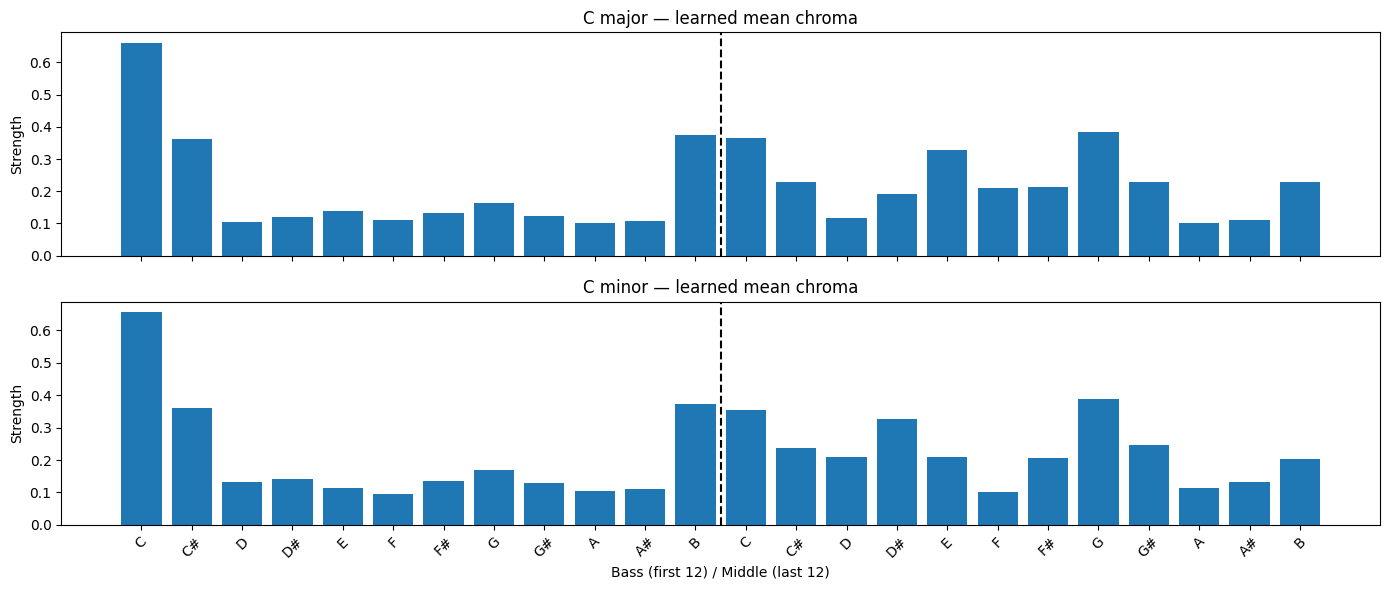

In [55]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for quality, title in enumerate(["C major", "C minor"]):
    axes[quality].bar(np.arange(24), model["means"][quality])
    axes[quality].axvline(11.5, color="black", linestyle="--")
    axes[quality].set_title(title + " — learned mean chroma")
    axes[quality].set_ylabel("Strength")
axes[1].set_xticks(np.arange(24), notes + notes, rotation=45)
axes[1].set_xlabel("Bass (first 12) / Middle (last 12)")
plt.tight_layout()
plt.show()


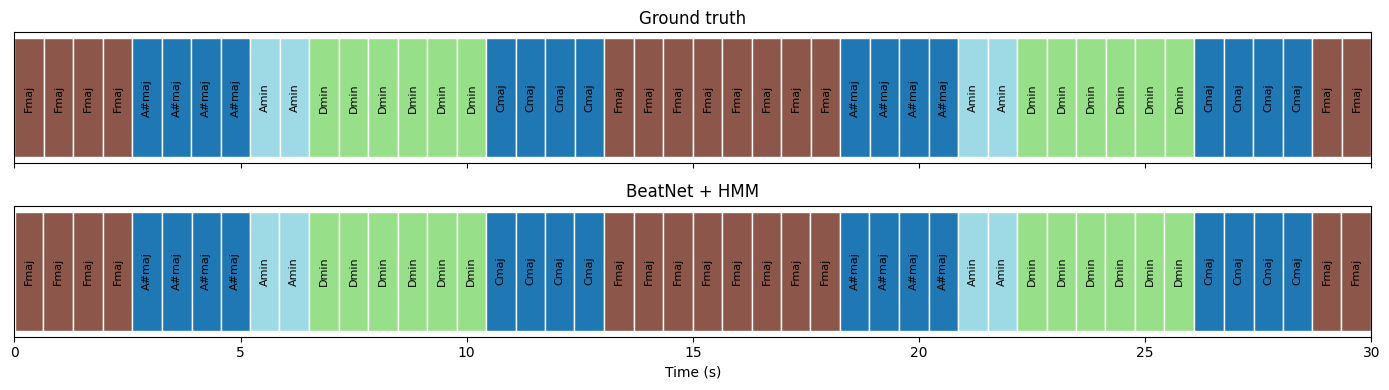

In [56]:
song_id = split["test"][0]
start_time, end_time = 0, 30
predictions = pd.read_csv(evaluation_path / f"{song_id}_predictions.csv")
predictions = predictions.rename(columns={"start_time_s": "start", "end_time_s": "end"})

fig, axes = plt.subplots(2, 1, figsize=(14, 4), sharex=True)
for ax, table, title in zip(axes, [ground_truth[song_id], predictions], ["Ground truth", "BeatNet + HMM"]):
    for row in table.itertuples():
        left, right = max(row.start, start_time), min(row.end, end_time)
        if right > left:
            color = plt.cm.tab20(chord_to_id.get(row.chord, 0) % 20)
            ax.barh(0, right - left, left=left, color=color, edgecolor="white")
            if right - left > 0.4:
                ax.text((left + right) / 2, 0, row.chord, ha="center", va="center", fontsize=8, rotation=90)
    ax.set_yticks([])
    ax.set_title(title)
axes[1].set_xlim(start_time, end_time)
axes[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

# Optional: uncomment to listen.
# display(Audio(filename=str(get_audio_path(song_id))))


## 14. Test confusion matrix and macro F1
This compares the complete pipeline at annotated quarter midpoints. It complements the exact time metric and uses only held-out test songs. Macro F1 weights chord classes equally, including any class absent from this test split as zero.


Test macro F1: 0.9024223635012748


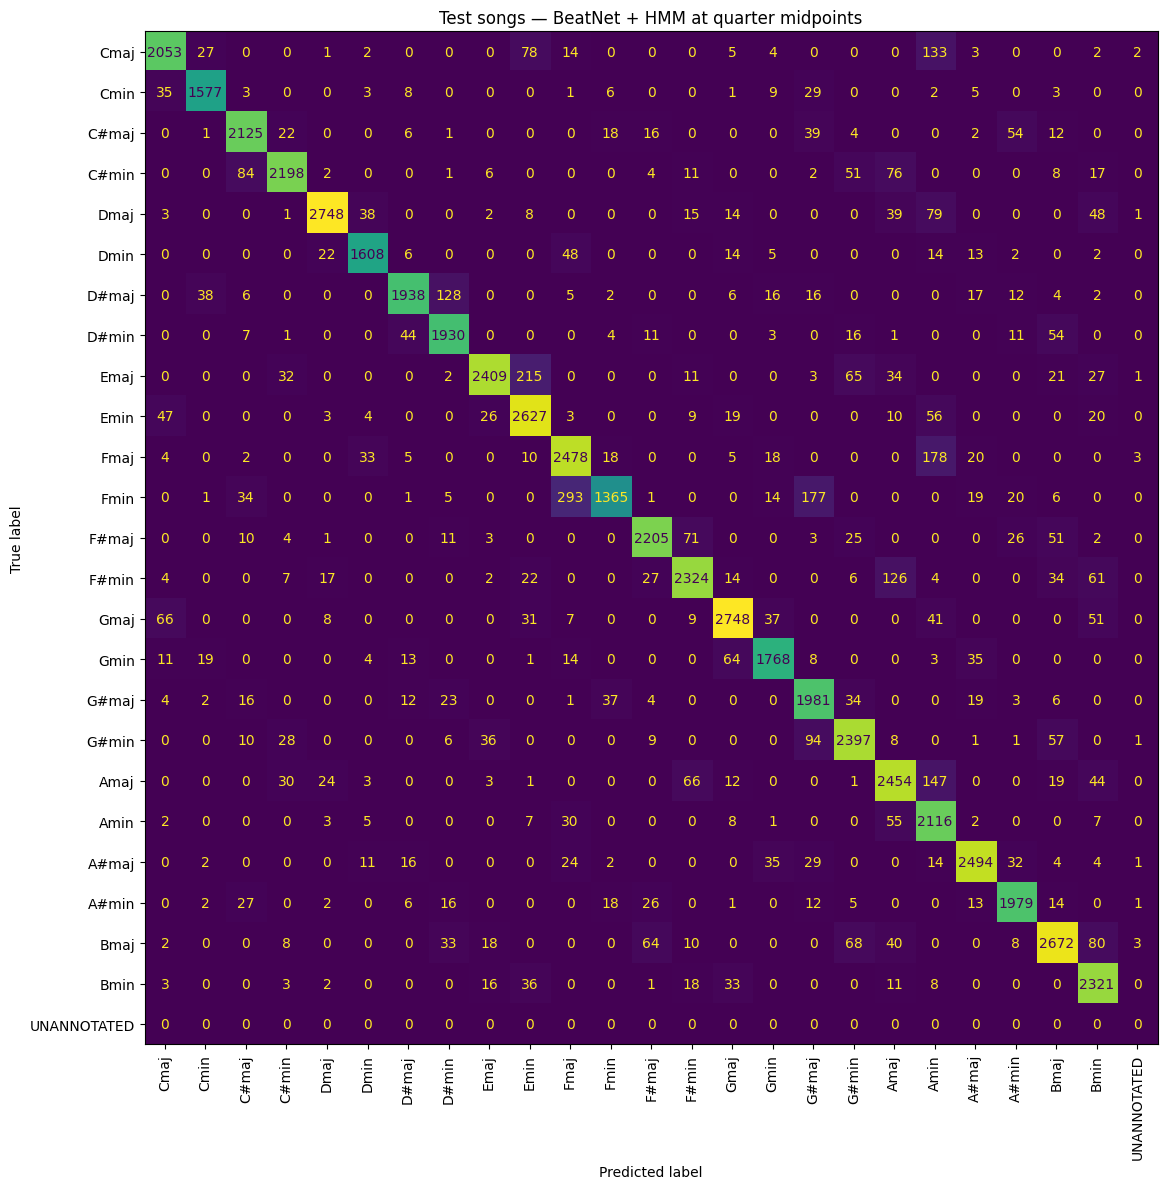

In [57]:
true_labels, predicted_labels = [], []
for song_id in split["test"]:
    truth = ground_truth[song_id]
    prediction_file = evaluation_path / f"{song_id}_predictions.csv"
    assert prediction_file.exists(), "Run test evaluation first."
    prediction = pd.read_csv(prediction_file).rename(columns={"start_time_s": "start", "end_time_s": "end"})
    sampled = labels_at((truth.start.to_numpy() + truth.end.to_numpy()) / 2, prediction)
    scored = truth.chord.ne("N").to_numpy()
    true_labels.extend(truth.chord.to_numpy()[scored])
    predicted_labels.extend(sampled[scored])

print("Test macro F1:", f1_score(true_labels, predicted_labels, labels=chords, average="macro", zero_division=0))
# Include missing predictions so the matrix does not silently omit them.
plot_labels = chords.tolist() + ["UNANNOTATED"]
matrix = confusion_matrix(true_labels, predicted_labels, labels=plot_labels)
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(matrix, display_labels=plot_labels).plot(ax=ax, xticks_rotation=90, values_format="d", colorbar=False)
plt.title("Test songs — BeatNet + HMM at quarter midpoints")
plt.tight_layout()
plt.show()


## 15. Annotate a new audio file with the saved model
After a restart, run the installation/import cell, then this cell and the function definitions in sections **4–9** plus BeatNet setup (section 8). Skip the dataset download, annotation, fitting, tuning and evaluation loops. Loading the saved model restores its sample rate, hop length and chord vocabulary.

Provide an audio path in Drive or upload audio into `/content`. This path uses **audio alone**; no ARFF, key, BPM or beat annotation is required. Output is a CSV with start/end times, chord, BeatNet quarter/bar estimates and local BPM. Adjacent equal chords can be merged into longer playing instructions. The model still predicts only major/minor triads and does not specify piano voicing or octave.


In [58]:
# Load independently: metadata checks against ground truth are needed for
# benchmarking, but an unseen audio file has no ground-truth metadata.
with np.load(model_path, allow_pickle=False) as saved:
    saved_settings = json.loads(str(saved["metadata"]))["settings"]
    assert saved_settings["features"] == "CQT84_C1_bass3_mid2_central90_L2"
    sample_rate = saved_settings["sr"]
    hop_length = saved_settings["hop"]
    chords = np.array(saved_settings["chords"])
    model = {"means": saved["means"], "covariances": saved["covariances"],
             "transitions": saved["transitions"], "weight": float(saved["weight"])}


In [59]:
# Change this path before running this optional cell.
new_audio_path = Path("/content/drive/MyDrive/my_song.wav")
if new_audio_path.exists():
    audio, sr = librosa.load(new_audio_path, sr=sample_rate, mono=True)
    duration = len(audio) / sr
    # Hash file contents so replacing a recording cannot reuse its old beats.
    audio_hash = hashlib.sha256()
    with open(new_audio_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            audio_hash.update(chunk)
    beat_file = results_path / (audio_hash.hexdigest()[:16] + "_beatnet_model1.npy")
    events = detect_beats(new_audio_path, beat_file)
    events = events[(events[:, 0] >= 0) & (events[:, 0] < duration)]
    assert len(events), "No beats detected: this model requires a beat grid."
    starts = events[:, 0]
    ends = np.append(starts[1:], duration)
    features = interval_features(compute_chroma(audio), starts, ends)
    labels = chords[viterbi(emission_scores(features, model), model["transitions"], model["weight"])]
    prediction = prediction_table(events, duration, labels)
    output = export_predictions(prediction, events)
    output_path = results_path / (new_audio_path.stem + "_chords.csv")
    output.to_csv(output_path, index=False)
    display(output.head(12))
    print("Saved:", output_path)

    # Merge neighboring equal chords into one longer instruction.
    groups = prediction.chord.ne(prediction.chord.shift()).cumsum()
    instructions = prediction.groupby(groups, sort=False).agg(
        start_time_s=("start", "first"), end_time_s=("end", "last"), chord=("chord", "first"))
    instructions.to_csv(results_path / (new_audio_path.stem + "_instructions.csv"), index=False)
else:
    print("Optional: set new_audio_path to your recording to export its chords.")


Optional: set new_audio_path to your recording to export its chords.


## 16. Use the separate preprocessing notebook
The old `AAM_EDA_refined_(2).ipynb` and its manual ARFF export snippet are no longer needed. Use **`AAM_Preprocessing_Colab.ipynb`** instead.

1. Run **steps 1–6** in the preprocessing notebook. It downloads the original AAM annotations, removes the verified surplus bars and exports one cleaned CSV per song.
2. Keep the same project folder in both notebooks: `PROJECT` in preprocessing must match `project_path` here.
3. The preprocessing output `PROJECT / "aam_cleaned_csv"` is the input `ground_truth_path` here. Files are named `0001_ground_truth.csv`, …, `1000_ground_truth.csv`.
4. Run this HMM notebook from section 1. The CSVs already contain `time_s`, `end_time_s`, `bar`, `quarter` and original-pitch `chord`; no ARFF conversion or extra code is required.

Preprocessing remains in its own notebook. This notebook handles chroma features, HMM training/loading, BeatNet, evaluation and prediction exports. The optional C-normalized CSV columns are not used as HMM targets.

## What the reported numbers mean
- The annotated-quarter HMM tests chord recognition with perfect timing.
- BeatNet + HMM tests the audio-to-chord pipeline, including beat errors.
- Correct-time ratio measures how much of the recording has the right chord at the right time.
- An onset MAE describes only matched changes; precision/recall show how many were missed or extra.
- AAM is procedurally generated. Held-out AAM results do not establish accuracy on arbitrary commercial recordings.

No trained checkpoint or measured AAM score is bundled here: run the two notebooks to produce them.
